In [ ]:
!python -c "import monai" || pip install -q "monai-weekly[nibabel, tqdm]"
!python -c "import matplotlib" || pip install -q matplotlib
%matplotlib inline


2024-04-27 13:39:18.761480: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-27 13:39:18.761546: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-27 13:39:18.762962: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
import os
import shutil
import tempfile
import time
import matplotlib.pyplot as plt

from monai.config import print_config
from monai.data import DataLoader, decollate_batch
from monai.handlers.utils import from_engine
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference
from monai.metrics import DiceMetric

from monai.transforms import (
    Activations,
    Activationsd,
    AsDiscrete,
    AsDiscreted,
    Compose,
    Invertd,
    LoadImaged,
    MapTransform,
    NormalizeIntensityd,
    Orientationd,
    Spacingd,
    EnsureTyped,
    EnsureChannelFirstd,
)
from monai.utils import set_determinism
import torch
import torch.nn as nn
from torch.nn.init import trunc_normal_

import torch

print_config()

MONAI version: 1.4.dev2416
Numpy version: 1.26.3
Pytorch version: 2.1.2
MONAI flags: HAS_EXT = False, USE_COMPILED = False, USE_META_DICT = False
MONAI rev id: d487995c8f685729ee5e1259f364034dab4811da
MONAI __file__: /opt/conda/lib/python3.10/site-packages/monai/__init__.py

Optional dependencies:
Pytorch Ignite version: 0.4.13
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.2.0
scikit-image version: 0.22.0
scipy version: 1.12.0
Pillow version: 9.5.0
Tensorboard version: 2.15.1
gdown version: NOT INSTALLED or UNKNOWN VERSION.
TorchVision version: 0.16.2
tqdm version: 4.66.1
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 5.9.3
pandas version: 2.2.0
einops version: NOT INSTALLED or UNKNOWN VERSION.
transformers version: 4.37.0
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.

For details about installing the optional dependencies, please visit:
    http

In [ ]:
directory = os.environ.get("MONAI_DATA_DIRECTORY")
root_dir = tempfile.mkdtemp() if directory is None else directory
print(root_dir)

/tmp/tmpi8tebe1b


In [ ]:
set_determinism(seed=0)

In [ ]:
train_transform = Compose(
    [
        # load 4 Nifti images and stack them together
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys="image"),
        EnsureTyped(keys=["image", "label"]),
        Orientationd(keys=["image", "label"], axcodes="RAS"),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest"),
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    ]
)
val_transform = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys="image"),
        EnsureTyped(keys=["image", "label"]),
        Orientationd(keys=["image", "label"], axcodes="RAS"),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest"),
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    ]
)

In [ ]:
new_directory = "/scratch/sputhuma"

os.chdir(new_directory)

In [ ]:
data_dir = 'TrainingData'
patient_ids = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)) and not d.startswith('.')]

data_dicts = [
    {'image': [os.path.join(data_dir, p_id, f'{p_id}_{m}.nii.gz') for m in ["flair", "t1", "t1ce", "t2"]],
     'label': os.path.join(data_dir, p_id, f'{p_id}_seg.nii.gz')}
    for p_id in patient_ids
]

train_files, val_files = data_dicts[:-10], data_dicts[-10:]

In [ ]:
train_ds = Dataset(data=train_files, transform=train_transforms)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=4)

val_ds = Dataset(data=val_files, transform=val_transforms)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=4)

image shape: torch.Size([4, 240, 240, 155])


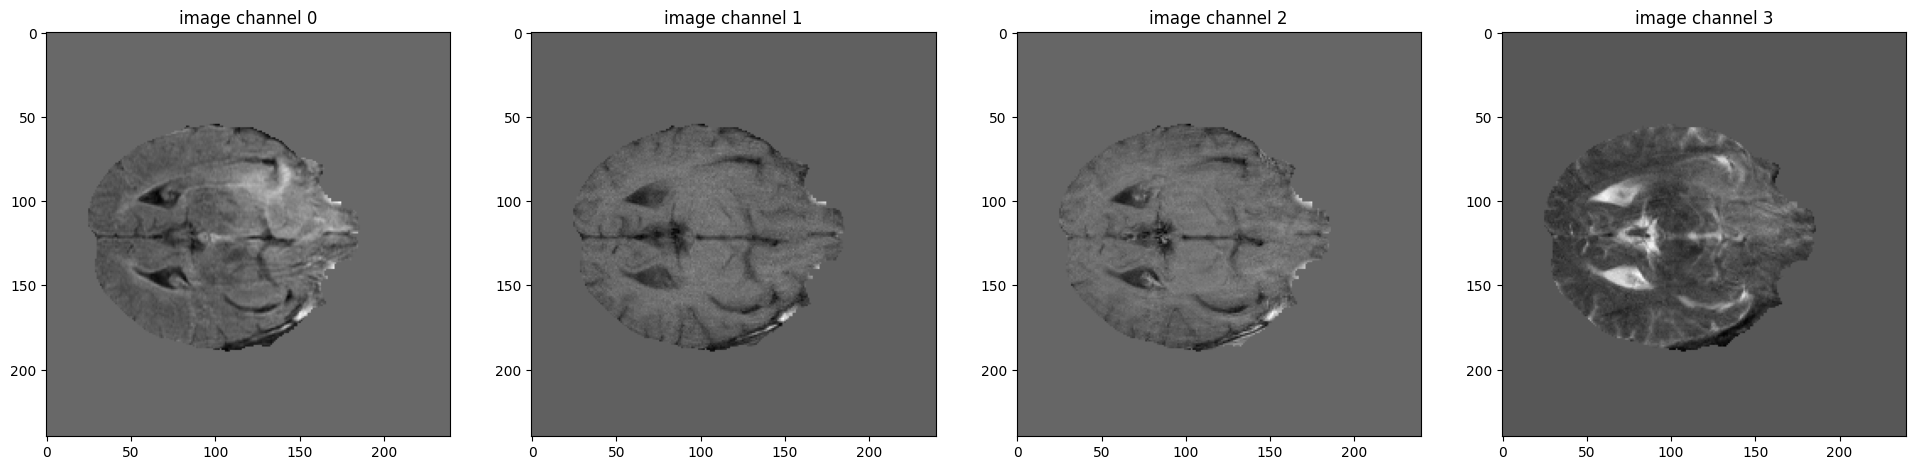

label shape: torch.Size([3, 240, 240, 155])


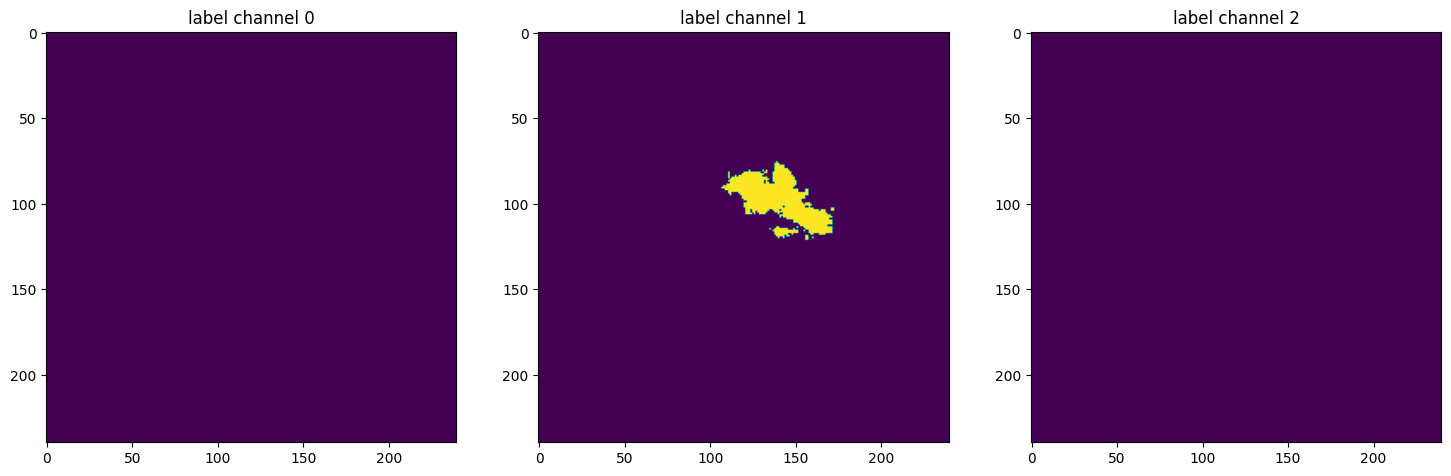

In [ ]:
# visualize one patient scan images along with lables
val_data_example = val_ds[4]
print(f"image shape: {val_data_example['image'].shape}")
plt.figure("image", (24, 6))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.title(f"image channel {i}")
    plt.imshow(val_data_example["image"][i, :, :, 60].detach().cpu(), cmap="gray")
plt.show()

print(f"label shape: {val_data_example['label'].shape}")
plt.figure("label", (18, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.title(f"label channel {i}")
    plt.imshow(val_data_example["label"][i, :, :, 60].detach().cpu())
plt.show()

## Model generation

In [ ]:

class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
        super(Mlp, self).__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

def window_partition(x, window_size):
    # x: (B, D, H, W, C)
    B, D, H, W, C = x.shape
    x = x.view(B, D // window_size, window_size, H // window_size, window_size, W // window_size, window_size, C)
    windows = x.permute(0, 1, 3, 5, 2, 4, 6, 7).contiguous().view(-1, window_size, window_size, window_size, C)
    return windows

def window_reverse(windows, window_size, D, H, W):
    B = windows.shape[0] // (D * H * W / window_size**3)
    x = windows.view(B, D // window_size, H // window_size, W // window_size, window_size, window_size, window_size, -1)
    x = x.permute(0, 1, 4, 2, 5, 3, 6, 7).contiguous().view(B, D, H, W, -1)
    return x


class WindowAttention(nn.Module):
    def __init__(self, dim, window_size, num_heads, qkv_bias=True, qk_scale=None, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        B_, *_, C = x.shape
         # Handle both flattened and non-flattened cases
        N = x.shape[1] * x.shape[2] * x.shape[3] if len(x.shape) == 5 else x.shape[1]
        x = x.view(B_, N, C)

        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        q = q * self.scale
        attn = (q @ k.transpose(-2, -1))
        attn = self.softmax(attn)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)

        # Reshape back to the original
        if len(x.shape) == 5:
            x = x.view(B_, *original_shape[1:-1], C)
        return x


    def extra_repr(self) -> str:
        return f'dim={self.dim}, window_size={self.window_size}, num_heads={self.num_heads}'

    def flops(self, N):
        # Calculate flops for 1 window with token length of N
        flops = 0
        flops += N * self.dim * 3 * self.dim
        flops += self.num_heads * N * (self.dim // self.num_heads) * N
        flops += self.num_heads * N * N * (self.dim // self.num_heads)
        # final projection
        flops += N * self.dim * self.dim
        return flops


class SwinTransformerBlock(nn.Module):
    def __init__(self, dim, input_resolution, num_heads, window_size, shift_size, mlp_ratio, qkv_bias, drop_rate, attn_drop, proj_drop):
        super().__init__()
        self.dim = dim
        self.input_resolution = input_resolution
        self.window_size = window_size
        self.shift_size = shift_size
        self.mlp_ratio = mlp_ratio
        self.num_heads = num_heads

        # Layer norm layers
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

        # Attention and MLP layers
        self.attn = WindowAttention(
            dim, window_size, num_heads, qkv_bias, attn_drop=attn_drop, proj_drop=proj_drop
        )
        self.mlp = Mlp(in_features=dim, hidden_features=int(dim * mlp_ratio), drop=drop_rate)

    def forward(self, x):
        B, D, H, W, C = x.shape
        # Compute total elements
        total_elements = D * H * W * C


        if total_elements % self.dim != 0:
            raise ValueError(f"Total elements ({total_elements}) in the tensor cannot be evenly divided by 'dim' ({self.dim})")
        # Compute new shape
        new_shape = (B, total_elements // self.dim, self.dim)
         # Reshape tensor to new shape
        x = x.reshape(new_shape)

        # Proceed with attention and other operations
        x = self.attn(x)
        x = self.mlp(x)

        # Optionally, reshape x back to the original dimensions for subsequent layers
        x = x.reshape(B, D, H, W, C)
        return x

class SwinTransformerUp(nn.Module):
    def __init__(self, dim, input_resolution):
        super().__init__()
        # Use trilinear for 3D
        self.up = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        self.conv = nn.Conv3d(dim, dim // 2, kernel_size=3, padding=1)
        self.norm = nn.BatchNorm3d(dim // 2)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, skip_connection):
        x = self.up(x)
        x = torch.cat([x, skip_connection], dim=1)
        x = self.conv(x)
        x = self.norm(x)
        return self.relu(x)

class SegmentationHead(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, upsampling):
        super().__init__()
        # Use Conv3d for 3D convolution
        self.conv = nn.Conv3d(in_channels, out_channels, kernel_size=kernel_size, padding=kernel_size // 2)
        # Use trilinear interpolation for 3D upsampling
        self.upsample = nn.Upsample(scale_factor=upsampling, mode='trilinear', align_corners=True) if upsampling > 1 else nn.Identity()

    def forward(self, x):
        x = self.conv(x)
        return self.upsample(x)

class SwinTransformerUp(nn.Module):
    def __init__(self, dim, input_resolution):
        super().__init__()
        # Use trilinear interpolation for 3D upsampling
        self.up = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        # Use 3D convolution
        self.conv = nn.Conv3d(dim, dim // 2, kernel_size=3, padding=1)
        # Use 3D batch normalization
        self.norm = nn.BatchNorm3d(dim // 2)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, skip_connection):
        x = self.up(x)
         # Concatenate along the channel dimension
        x = torch.cat([x, skip_connection], dim=1)
        x = self.conv(x)
        x = self.norm(x)
        return self.relu(x)

import torch.nn as nn

class SwinTransformerStage(nn.Module):
    def __init__(self, dim, input_resolution, depth, num_heads, window_size, mlp_ratio, qkv_bias, drop_rate, attn_drop_rate,proj_drop):
        super().__init__()

        assert len(window_size) == 3 and len(input_resolution) == 3, "Window size and input resolution must be three-dimensional"

        self.layers = nn.ModuleList([
            SwinTransformerBlock(
                dim=dim,
                input_resolution=input_resolution,
                num_heads=num_heads,
                window_size=window_size,
                shift_size=(window_size[0] // 2 if i % 2 else 0,
                            window_size[1] // 2 if i % 2 else 0,
                            window_size[2] // 2 if i % 2 else 0),
                mlp_ratio=mlp_ratio,
                qkv_bias=qkv_bias,
                drop_rate=drop_rate,
                attn_drop=attn_drop_rate,
                proj_drop=proj_drop
            )
            for i in range(depth)
        ])

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x



In [ ]:
import torch.nn as nn

class HTCNet(nn.Module):
    def __init__(self, config, img_size, num_classes):
        super().__init__()


        self.encoder_stages = nn.ModuleList()

        scalar_window_size = 7
        window_size_3d = (scalar_window_size, scalar_window_size, scalar_window_size)
        proj_drop = 0.1
        # Apply the division for each element in the img_size tuple
        input_resolution_stage1 = (img_size[0] // 4, img_size[1] // 4, img_size[2] // 4)
        input_resolution_stage2 = (img_size[0] // 8, img_size[1] // 8, img_size[2] // 8)

        stage1 = SwinTransformerStage(
            dim=96,
            input_resolution= input_resolution_stage1,
            depth=2,
            num_heads=3,
            window_size=window_size_3d,
            mlp_ratio=4,
            qkv_bias=True,
            drop_rate=0.1,
            attn_drop_rate=0.05,
            proj_drop=proj_drop
        )
        stage2 = SwinTransformerStage(
            dim=192,
            input_resolution= input_resolution_stage2,
            depth=2,
            num_heads=6,
            window_size=window_size_3d,
            mlp_ratio=4,
            qkv_bias=True,
            drop_rate=0.1,
            attn_drop_rate=0.05,
            proj_drop=proj_drop
        )


        self.encoder_stages.extend([stage1, stage2])

    def forward(self, x):
        for stage in self.encoder_stages:
            x = stage(x)
        return x




In [ ]:
max_epochs = 10

loss_function = DiceLoss(smooth_nr=0, smooth_dr=1e-5, squared_pred=True, to_onehot_y=False, sigmoid=True)
optimizer = torch.optim.Adam(model.parameters(), 1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)

dice_metric = DiceMetric(include_background=True, reduction="mean")
dice_metric_batch = DiceMetric(include_background=True, reduction="mean_batch")

post_trans = Compose([Activations(sigmoid=True), AsDiscrete(threshold=0.5)])



In [ ]:
config = {}
img_size = (240, 240, 155)
num_classes = 4

model = HTCNet(config=config, img_size=img_size, num_classes=num_classes)

In [ ]:
best_metric = -1
best_metric_epoch = -1
best_metrics_epochs_and_time = [[], [], []]
epoch_loss_values = []
metric_values = []

total_start = time.time()
for epoch in range(max_epochs):
    epoch_start = time.time()
    print("-" * 10)
    print(f"epoch {epoch + 1}/{max_epochs}")
    model.train()
    epoch_loss = 0
    step = 0
    for batch_data in train_loader:
        step_start = time.time()
        step += 1
        inputs, labels = (
            batch_data["image"].to(device),
            batch_data["label"].to(device),
        )
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = loss_function(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
    lr_scheduler.step()
    epoch_loss /= step
    epoch_loss_values.append(epoch_loss)
    print(f"epoch {epoch + 1} average loss: {epoch_loss:.4f}")

    if (epoch + 1) % val_interval == 0:
        model.eval()
        with torch.no_grad():
            for val_data in val_loader:
                val_inputs, val_labels = (
                    val_data["image"].to(device),
                    val_data["label"].to(device),
                )
                val_outputs = inference(val_inputs)
                val_outputs = [post_trans(i) for i in decollate_batch(val_outputs)]
                dice_metric(y_pred=val_outputs, y=val_labels)
                dice_metric_batch(y_pred=val_outputs, y=val_labels)

            metric = dice_metric.aggregate().item()
            metric_values.append(metric)
            metric_batch = dice_metric_batch.aggregate()
            dice_metric.reset()
            dice_metric_batch.reset()

            if metric > best_metric:
                best_metric = metric
                best_metric_epoch = epoch + 1
                best_metrics_epochs_and_time[0].append(best_metric)
                best_metrics_epochs_and_time[1].append(best_metric_epoch)
                best_metrics_epochs_and_time[2].append(time.time() - total_start)

            print(
                f"current epoch: {epoch + 1} current mean dice: {metric:.4f}"
                f"\nbest mean dice: {best_metric:.4f}"
                f" at epoch: {best_metric_epoch}"
            )
    print(f"time consuming of epoch {epoch + 1} is: {(time.time() - epoch_start):.4f}")
total_time = time.time() - total_start

----------
epoch 1/10
epoch 1 average loss: 0.9190
current epoch: 1 current mean dice: 0.4051
best mean dice: 0.4051 at epoch: 1
time consuming of epoch 1 is: 563.8446
----------
epoch 2/10
epoch 2 average loss: 0.8773
current epoch: 2 current mean dice: 0.3782
best mean dice: 0.4051 at epoch: 1
time consuming of epoch 2 is: 564.2138
----------
epoch 3/10
epoch 3 average loss: 0.8041
current epoch: 3 current mean dice: 0.5209
best mean dice: 0.5209 at epoch: 3
time consuming of epoch 3 is: 564.8535
----------
epoch 4/10
epoch 4 average loss: 0.6940
current epoch: 4 current mean dice: 0.5913
best mean dice: 0.5913 at epoch: 4
time consuming of epoch 4 is: 565.7036
----------
epoch 5/10
epoch 5 average loss: 0.5822
current epoch: 5 current mean dice: 0.5803
best mean dice: 0.5913 at epoch: 4
time consuming of epoch 5 is: 565.1466
----------
epoch 6/10
epoch 6 average loss: 0.5014
current epoch: 6 current mean dice: 0.6116
best mean dice: 0.6116 at epoch: 6
time consuming of epoch 6 is: 5

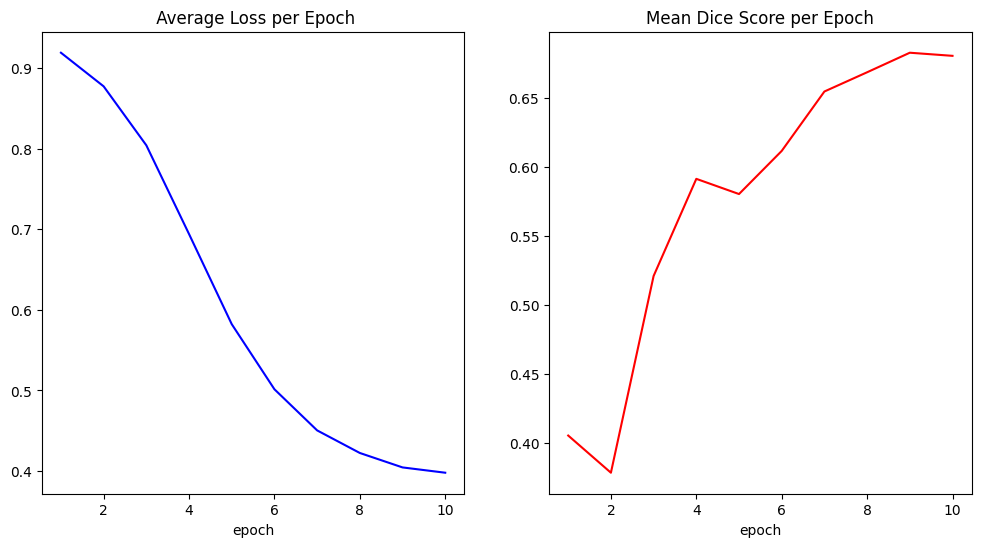

'plt.figure("train", (18, 6))\nplt.subplot(1, 3, 1)\nplt.title("Val Mean Dice TC")\nx = [val_interval * (i + 1) for i in range(len(metric_values_tc))]\ny = metric_values_tc\nplt.xlabel("epoch")\nplt.plot(x, y, color="blue")\nplt.subplot(1, 3, 2)\nplt.title("Val Mean Dice WT")\nx = [val_interval * (i + 1) for i in range(len(metric_values_wt))]\ny = metric_values_wt\nplt.xlabel("epoch")\nplt.plot(x, y, color="brown")\nplt.subplot(1, 3, 3)\nplt.title("Val Mean Dice ET")\nx = [val_interval * (i + 1) for i in range(len(metric_values_et))]\ny = metric_values_et\nplt.xlabel("epoch")\nplt.plot(x, y, color="purple")\nplt.show()   '

In [ ]:
plt.figure("train", (12, 6))
plt.subplot(1, 2, 1)
plt.title(" Average Loss per Epoch")
x = [i + 1 for i in range(len(epoch_loss_values))]
y = epoch_loss_values
plt.xlabel("epoch")
plt.plot(x, y, color="blue")
plt.subplot(1, 2, 2)
plt.title("Mean Dice Score per Epoch")
x = [val_interval * (i + 1) for i in range(len(metric_values))]
y = metric_values
plt.xlabel("epoch")
plt.plot(x, y, color="red")
plt.show()



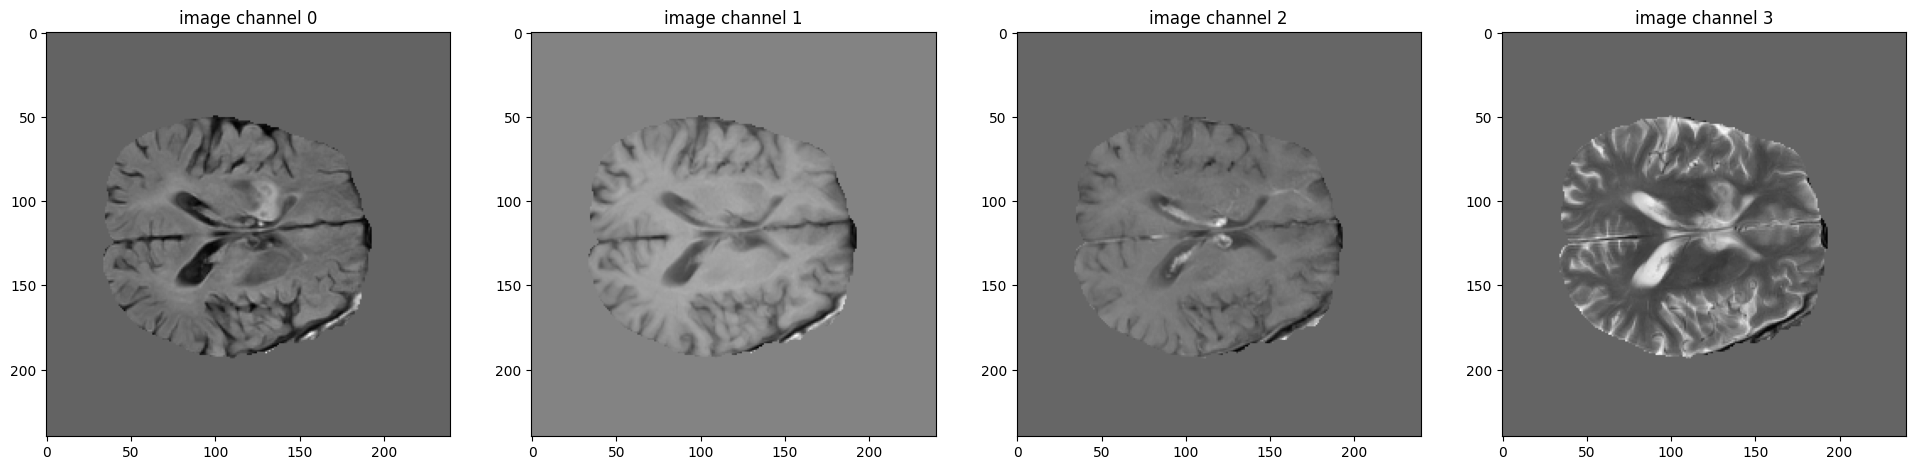

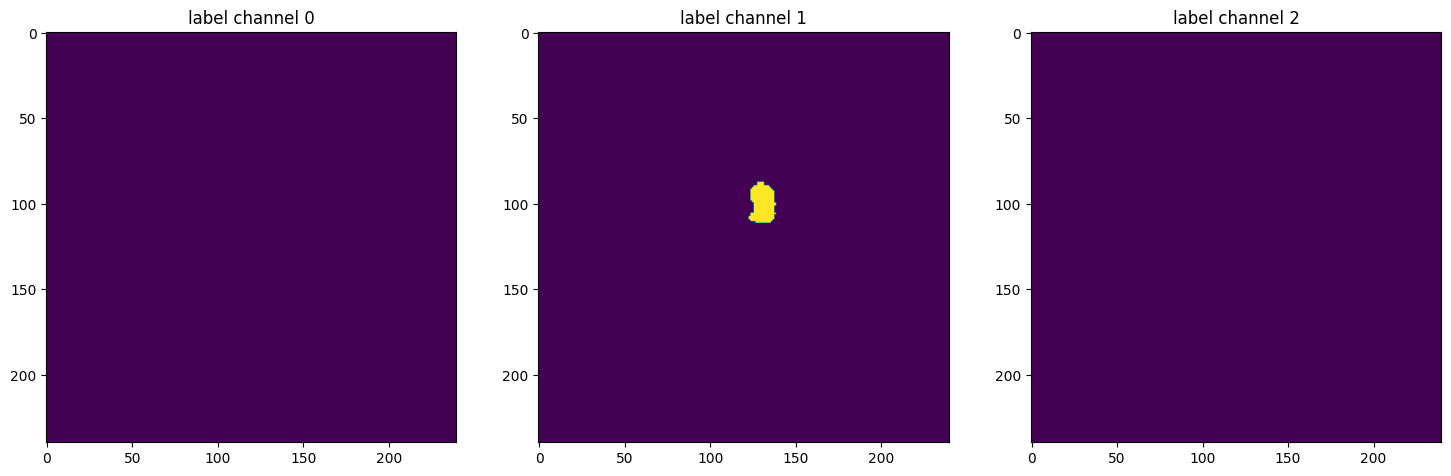

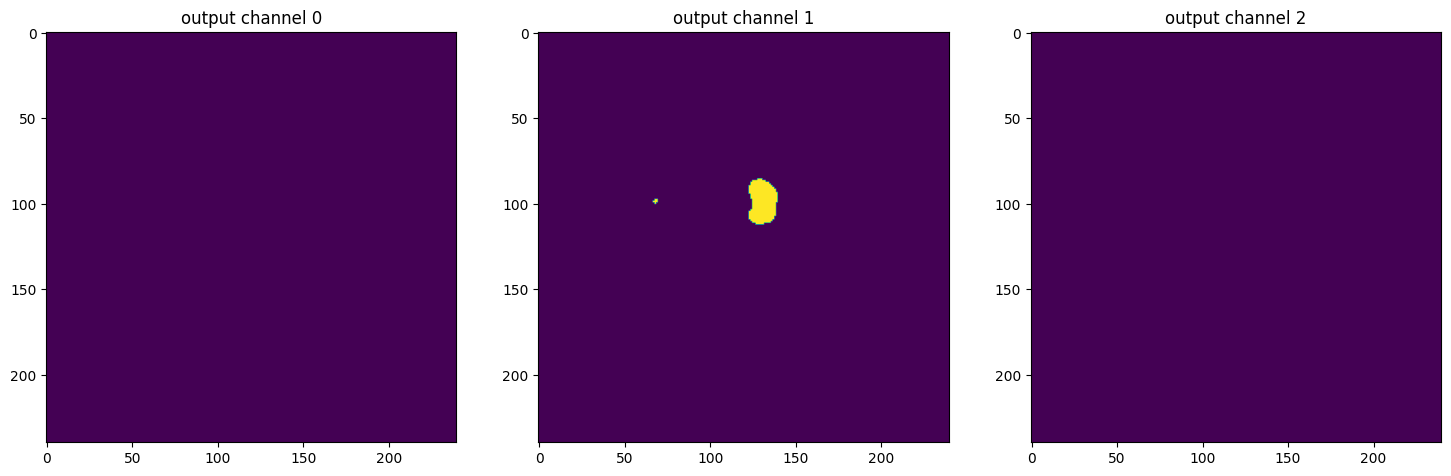

In [ ]:
model.load_state_dict(torch.load(os.path.join(root_dir, "best_metric_model.pth")))
model.eval()
with torch.no_grad():
    # Evaluate and visualize the model output
    val_input = val_ds[3]["image"].unsqueeze(0).to(device)
    roi_size = (128, 128, 64)
    sw_batch_size = 4
    val_output = inference(val_input)
    val_output = post_trans(val_output[0])
    plt.figure("image", (24, 6))
    for i in range(4):
        plt.subplot(1, 4, i + 1)
        plt.title(f"image channel {i}")
        plt.imshow(val_ds[3]["image"][i, :, :, 72].detach().cpu(), cmap="gray")
    plt.show()
    # visualize the 3  label channels corresponding to image
    plt.figure("label", (18, 6))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.title(f"label channel {i}")
        plt.imshow(val_ds[3]["label"][i, :, :, 72].detach().cpu())
    plt.show()
    # visualize the 3 model output channels  corresponding to  image
    plt.figure("output", (18, 6))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.title(f"output channel {i}")
        plt.imshow(val_output[i, :, :, 72].detach().cpu())
    plt.show()

In [ ]:
import numpy as np

def overlay_label_on_image(image, label):
    overlaid_images = []
    for i in range(image.shape[0]):
        overlaid_image = np.zeros_like(image[i])
        # Overlay each label channel onto the corresponding image channel
        for j in range(min(image.shape[0], label.shape[0])):
            overlaid_image[label[j] > 0] = label[j][label[j] > 0]
        overlaid_images.append(overlaid_image)
    return np.stack(overlaid_images)

overlay = overlay_label_on_image(val_ds[3]["image"].detach().cpu().numpy(), val_ds[3]["label"].detach().cpu().numpy())


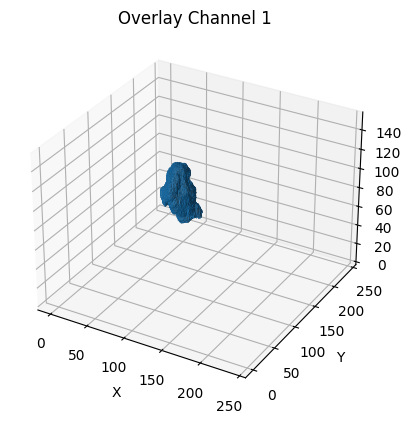

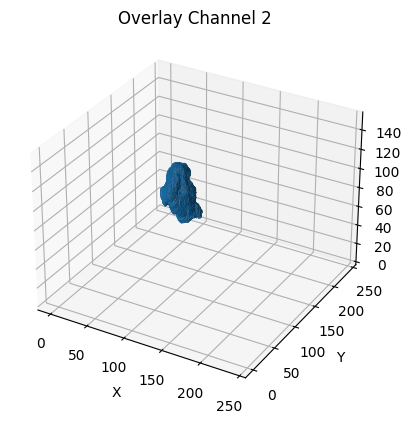

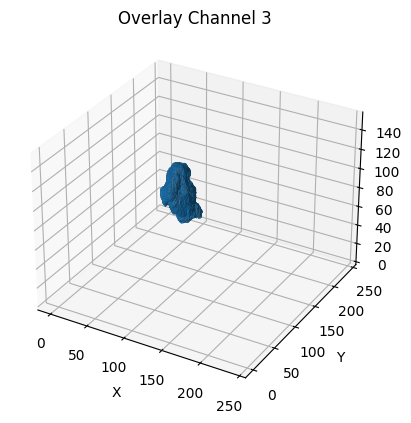

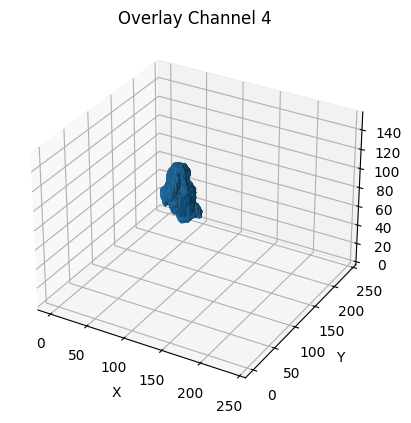

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Iterate over each channel for generating the image
for i in range(overlay.shape[0]):

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')


    ax.voxels(overlay[i])

    # Set  title and labels
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(f'Overlay Channel {i+1}')


    plt.show()


In [ ]:
!pip install ipyvolume


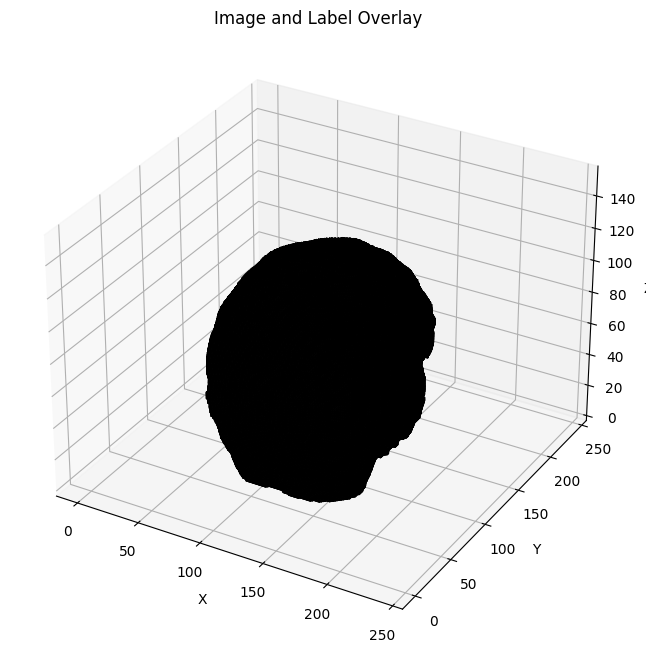

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Convert image and label to numpy arrays
image_np = val_ds[3]["image"].detach().cpu().numpy()
label_np = val_ds[3]["label"].detach().cpu().numpy()


fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')


ax.voxels(image_np[0], facecolors='gray', edgecolors='k')

# the label on the image
for i in range(3):
    ax.voxels(label_np[i], facecolors=f'C{i}', edgecolors='k')

# Set title and labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Image and Label Overlay')


plt.show()
